# Step 33 — Association coverage and diagnostic bar charts

Run after step 32. The notebook contains its plotting implementation directly, with shared date/save helpers. It reads saved CSVs and writes four full-width daily bar charts plus supporting daily CSVs. It does not reassign or validate picks, and does not plot waveforms with pick markers yet.

## Reading the figures

| Output | Meaning and denominator |
|---|---|
| `33_waveform_coverage.png` | Stacked WAV+PICKS and WAV_ONLY counts. Their sum should equal the waveform-index count for each recorded start day; that total is not stacked again. |
| `33_event_types.png` | Stacked counts of all three mutually exclusive container classes. These are association containers, not independent earthquakes. |
| `33_mean_picks_per_event.png` | Mean number of mapped picks among WAV+PICKS containers, grouped by waveform start date. Days without such containers are undefined and remain blank rather than becoming zero picks/event. |
| `33_primary_pick_fraction.png` | Primary picks divided by all mapped picks on each pick's own recorded date, including PICKS_ONLY records. A high fraction reflects source availability/priority, not confidence or accuracy. Days without picks are undefined. |

Daily count charts include every calendar day in the union of waveform and event coverage and use bars one day wide, without gaps between adjacent days. Time parsing as UTC is computational representation only; separate acquisition clocks, drift and source offsets remain unresolved. An event crossing midnight is counted on its start day; individual picks use their own dates.

The mean-pick computation joins explicitly on event ID rather than assigning dates by row position. `step30_event_csv` is retained in the settings for continuity but the plotted summaries use the step-32 catalogue and map. Outputs overwrite matching names in the external QC directory. The saved review is step 34.

## 1. Configuration

Inspect source paths, output paths and tolerances. This cell resolves configuration without running association or plotting.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

# Find the adjacent local package whether Jupyter starts here or in the project root.
_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'pinatubo_steps').is_dir()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Open this notebook from the pipeline folder or project root.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from pinatubo_steps.config import pipeline_paths

CONFIG_FILE = None  # Default: conversion_config.json; or set an explicit JSON path.
P = pipeline_paths(config_file=CONFIG_FILE)
DATA_TOP = Path(P['DATA_TOP'])
print('Configuration:', P['CONFIG_FILE'])
print('External outputs:', P['OUTPUT_ROOT'])

SETTINGS = dict(
    waveform_index=P['WAVEFORM_INDEX'],
    step30_event_csv=P['INDIV_WAVEFORM_EVENT_CSV'],
    event_catalog=P['WAVEFORM_PICK_EVENT_INDEX'],
    pick_map=P['PICK_MAP_CSV'],
    outdir=P['STEP33_DIR'],
)
display(SETTINGS)

Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
External outputs: /Users/thompsong/work/Pinatubo1991Processing/converted


{'waveform_index': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/10_waveform_index.csv',
 'step30_event_csv': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/30_individual_waveform_event_index.csv',
 'event_catalog': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/32_waveform_pick_event_index.csv',
 'pick_map': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/32_waveform_pick_event_map.csv',
 'outdir': '/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association'}

## 2. Implementation

These definitions make the workflow inspectable here. Defining them does not write files; the run cell below executes them.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pinatubo_steps.shared import to_dt, savefig

def run(*, waveform_index, step30_event_csv, event_catalog, pick_map, outdir):
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    dtype = {k: str for k in ('event_id', 'waveform_id', 'pick_id')}
    wav = pd.read_csv(waveform_index, dtype=dtype, low_memory=False)
    ev = pd.read_csv(event_catalog, dtype=dtype, low_memory=False)
    picks = pd.read_csv(pick_map, dtype=dtype, low_memory=False)
    wav['date'] = to_dt(wav['starttime']).dt.floor('D')
    ev['date'] = to_dt(ev['starttime']).dt.floor('D')
    picks['date'] = to_dt(picks['pick_time']).dt.floor('D')
    bounds = pd.concat([wav['date'], ev['date']]).dropna()
    if bounds.empty:
        raise ValueError('No valid waveform/event dates to plot.')
    days = pd.date_range(bounds.min(), bounds.max(), freq='D', name='date')
    daily_wav = wav.groupby('date').size().reindex(days, fill_value=0).rename('n_waveforms')
    daily_ev = (ev.groupby(['date', 'event_class']).size().unstack(fill_value=0)
                .reindex(index=days, columns=['WAV+PICKS', 'WAV_ONLY', 'PICKS_ONLY'], fill_value=0))
    daily = pd.concat([daily_wav, daily_ev], axis=1)
    daily['waveform_count_difference'] = daily['n_waveforms'] - daily['WAV+PICKS'] - daily['WAV_ONLY']
    daily.to_csv(outdir / '33_daily_association_counts.csv')

    def bars(table, title, ylabel, filename):
        fig, ax = plt.subplots(figsize=(12, 4))
        bottom = pd.Series(0.0, index=table.index)
        for name in table.columns:
            ax.bar(table.index, table[name], bottom=bottom, width=1.0,
                   align='edge', linewidth=0, label=name)
            bottom = bottom + table[name].fillna(0)
        locator = mdates.AutoDateLocator(minticks=5, maxticks=12)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set_xlim(days[0], days[-1] + pd.Timedelta(days=1))
        ax.set(title=title, ylabel=ylabel, xlabel='Recorded date (clock offsets not independently verified)')
        ax.set_ylim(bottom=0)
        if 'fraction' in filename:
            ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
        savefig(outdir / filename)

    bars(daily_ev[['WAV+PICKS', 'WAV_ONLY']], 'Waveform containers per day', 'Waveform files', '33_waveform_coverage.png')
    bars(daily_ev, 'Association containers per day (not unique earthquakes)', 'Containers', '33_event_types.png')
    counts = picks.groupby('event_id').size().rename('n_mapped_picks')
    linked = ev[ev['event_class'].eq('WAV+PICKS')][['event_id', 'date']].merge(
        counts, left_on='event_id', right_index=True, how='left', validate='one_to_one')
    daily_mean = linked.groupby('date')['n_mapped_picks'].mean().reindex(days)
    daily_mean.rename('mean_picks').to_csv(outdir / '33_mean_picks_per_event.csv')
    bars(daily_mean.rename('Mean picks').to_frame(), 'Mean picks per waveform container with picks', 'Mean picks/container', '33_mean_picks_per_event.png')
    pri = picks.groupby(['date', 'pick_priority']).size().unstack(fill_value=0).reindex(days, fill_value=0)
    numerator = pri['primary'] if 'primary' in pri else pd.Series(0, index=days)
    frac = numerator / pri.sum(axis=1).replace(0, float('nan'))
    frac.rename('primary_fraction').to_csv(outdir / '33_primary_pick_fraction.csv')
    bars(frac.rename('Primary fraction').to_frame(), 'Primary fraction of all mapped picks (including pick-only)', 'Fraction', '33_primary_pick_fraction.png')
    print('Step 33 complete:', outdir)
    print('Days with waveform count discrepancies:', daily['waveform_count_difference'].ne(0).sum())
    return dict(daily=daily, daily_mean=daily_mean, primary_fraction=frac, ev=ev, picks=picks)

## 3. Run

This cell reads the configured inputs and replaces configured outputs. Review the summary before continuing.

In [3]:
result = run(**SETTINGS)

Step 33 complete: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association
Days with waveform count discrepancies: 0


In [4]:
# Preview returned tables and summary objects without reloading output files.
for name, value in result.items():
    print(name)
    display(value.head() if hasattr(value, 'head') else
            value[:5] if isinstance(value, list) else value)


daily


,n_waveforms,WAV+PICKS,WAV_ONLY,PICKS_ONLY,waveform_count_difference
date,,,,,
1991-05-01 00:00:00+00:00,24,24,0,0,0
1991-05-02 00:00:00+00:00,6,3,3,0,0
1991-05-03 00:00:00+00:00,32,32,0,0,0
1991-05-04 00:00:00+00:00,74,63,11,0,0
1991-05-05 00:00:00+00:00,40,30,10,0,0


daily_mean


date
1991-05-01 00:00:00+00:00    2.041667
1991-05-02 00:00:00+00:00    2.000000
1991-05-03 00:00:00+00:00    2.093750
1991-05-04 00:00:00+00:00    2.460317
1991-05-05 00:00:00+00:00    2.533333
Freq: D, Name: n_mapped_picks, dtype: float64

primary_fraction


date
1991-05-01 00:00:00+00:00    0.0
1991-05-02 00:00:00+00:00    0.0
1991-05-03 00:00:00+00:00    0.0
1991-05-04 00:00:00+00:00    0.0
1991-05-05 00:00:00+00:00    0.0
Freq: D, dtype: float64

ev


,event_id,event_class,waveform_id,wav_file,starttime,endtime,has_waveform,has_primary_picks,has_secondary_picks,n_picks_total,n_primary_picks,n_secondary_picks,date
0,pick_91060310,PICKS_ONLY,NaN,NaN,1991-06-03T17:17:47.410000+00:00,1991-06-03T17:18:48.220000+00:00,False,True,False,10,10,0,1991-06-03 00:00:00+00:00
1,pick_91061006,PICKS_ONLY,NaN,NaN,1991-06-10T08:10:31.600000+00:00,1991-06-10T08:10:52.950000+00:00,False,True,False,2,2,0,1991-06-10 00:00:00+00:00
2,pick_910610A6,PICKS_ONLY,NaN,NaN,1991-06-10T08:10:31.600000+00:00,1991-06-10T08:10:32.180000+00:00,False,True,False,2,2,0,1991-06-10 00:00:00+00:00
3,pick_910610B6,PICKS_ONLY,NaN,NaN,1991-06-10T08:10:55.730000+00:00,1991-06-10T08:10:55.730000+00:00,False,True,False,1,1,0,1991-06-10 00:00:00+00:00
4,pick_pinaug91_block0000,PICKS_ONLY,NaN,NaN,1991-07-31T16:06:14.810000+00:00,1991-07-31T16:06:19.510000+00:00,False,False,True,4,0,4,1991-07-31 00:00:00+00:00


picks


,event_id,event_class,waveform_id,wav_file,pick_id,pick_source,pick_priority,pick_group_id,event_id_source,seed_id,...,pick_time,time_offset,raw_line,raw_lineno,pha_file,original_seed_id,include_waveform_overlay,waveform_seed_id,waveform_overlay_rule,date
0,pick_91060310,PICKS_ONLY,NaN,NaN,indpha_91060310_334,individual,primary,91060310,individual_pha_filename,XB.BUG..EHZ,...,1991-06-03T17:17:48.670000+00:00,NaN,BUGZ PD0 910603171748.67 ...,10,91060310.PHA,XB.BUG..EHZ,False,NaN,no_associated_waveform,1991-06-03 00:00:00+00:00
1,pick_91060310,PICKS_ONLY,NaN,NaN,indpha_91060310_335,individual,primary,91060310,individual_pha_filename,XB.BUR..EHZ,...,1991-06-03T17:17:49.170000+00:00,NaN,BURZ P 3 910603171749.17,7,91060310.PHA,XB.BUR..EHZ,False,NaN,no_associated_waveform,1991-06-03 00:00:00+00:00
2,pick_91060310,PICKS_ONLY,NaN,NaN,indpha_91060310_336,individual,primary,91060310,individual_pha_filename,XB.CAB..EHZ,...,1991-06-03T17:17:57.960000+00:00,NaN,CABZ P 5 910603171757.96,9,91060310.PHA,XB.CAB..EHZ,False,NaN,no_associated_waveform,1991-06-03 00:00:00+00:00
3,pick_91060310,PICKS_ONLY,NaN,NaN,indpha_91060310_337,individual,primary,91060310,individual_pha_filename,XB.GRN..EHZ,...,1991-06-03T17:17:48.230000+00:00,NaN,GRNZ P 4 910603171748.23 48.22 S 3,2,91060310.PHA,XB.GRN..EHZ,False,NaN,no_associated_waveform,1991-06-03 00:00:00+00:00
4,pick_91060310,PICKS_ONLY,NaN,NaN,indpha_91060310_338,individual,primary,91060310,individual_pha_filename,XB.GRN..EHZ,...,1991-06-03T17:18:48.220000+00:00,NaN,GRNZ P 4 910603171748.23 48.22 S 3,2,91060310.PHA,XB.GRN..EHZ,False,NaN,no_associated_waveform,1991-06-03 00:00:00+00:00


4 saved PNG figures; showing up to four.
/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association/33_event_types.png


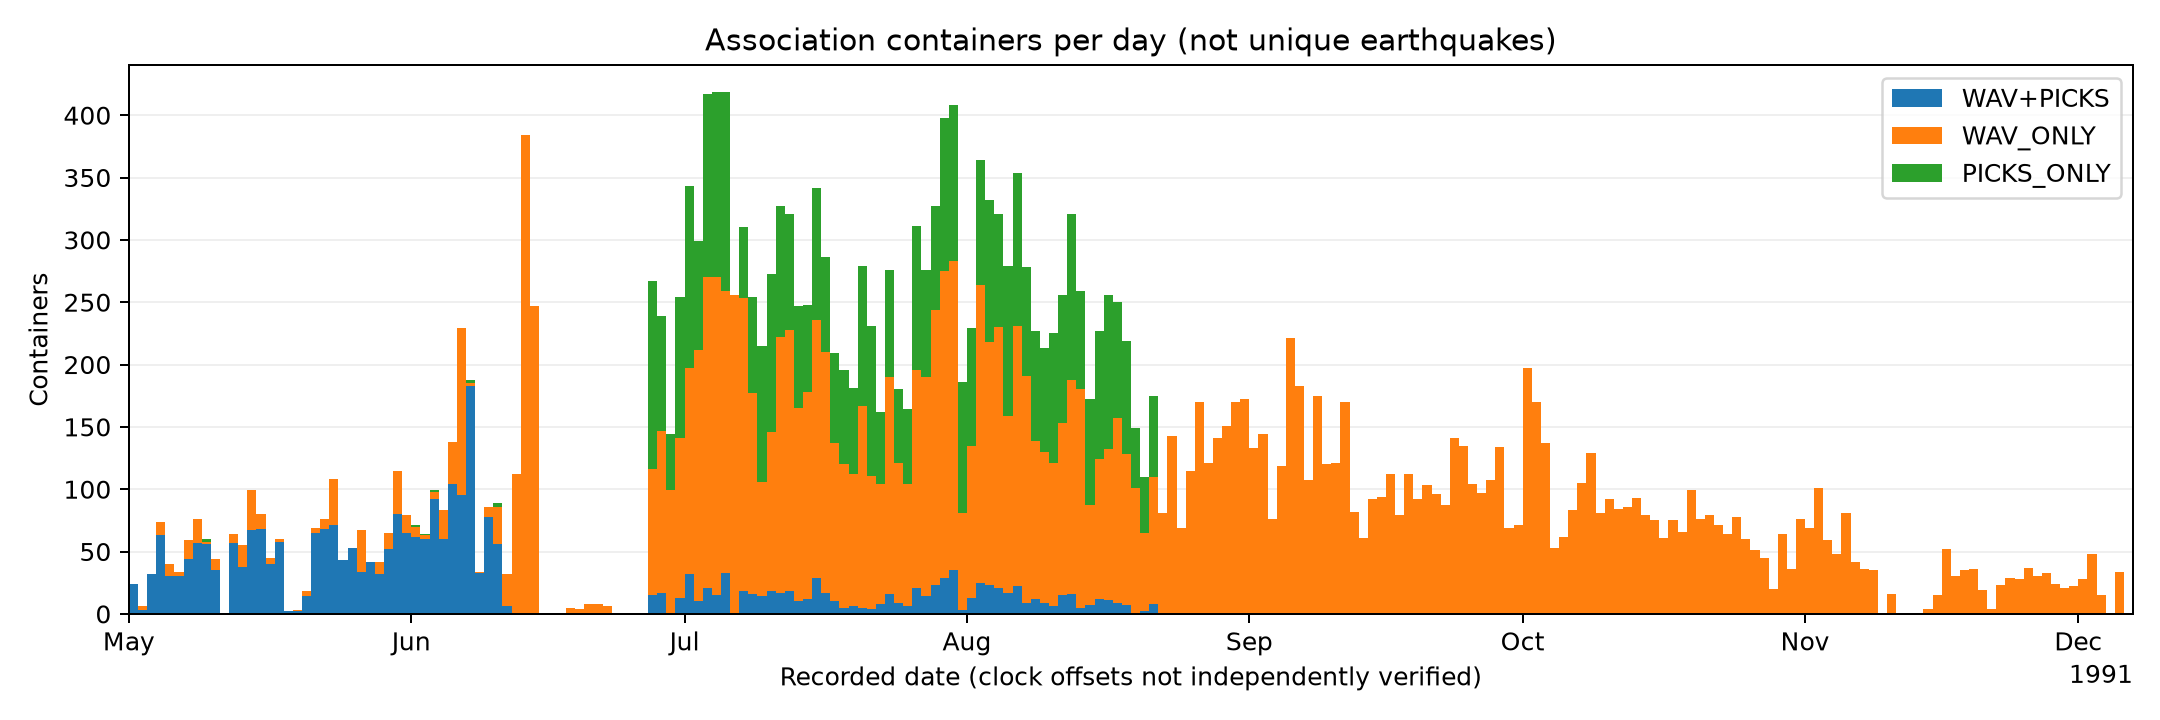

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association/33_mean_picks_per_event.png


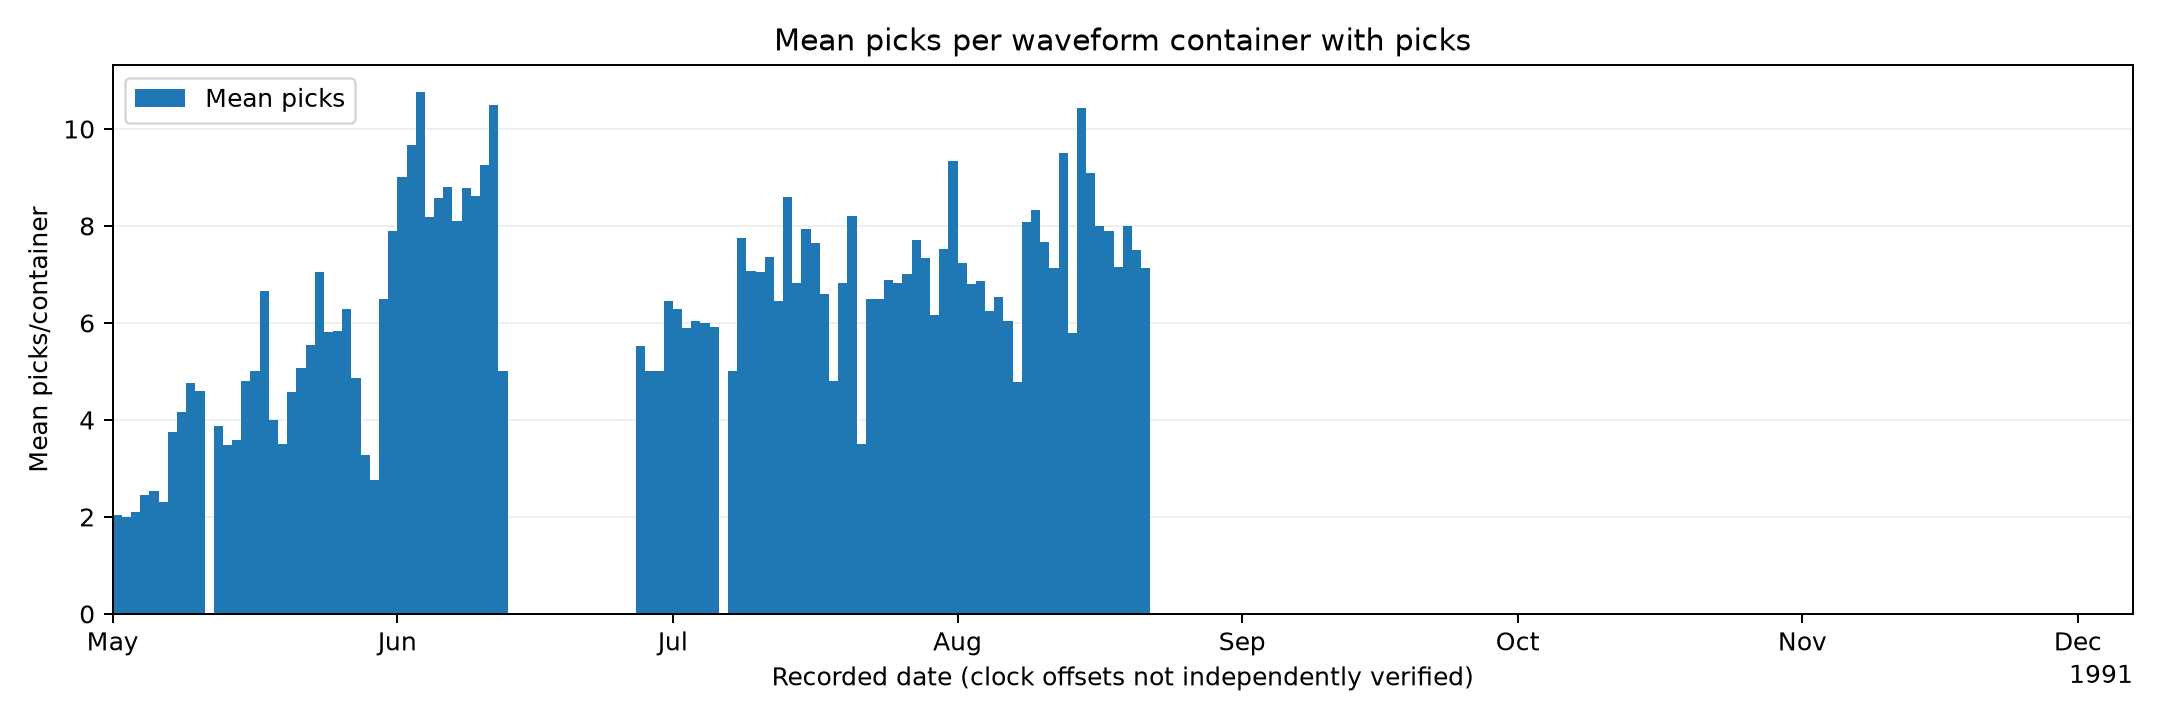

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association/33_primary_pick_fraction.png


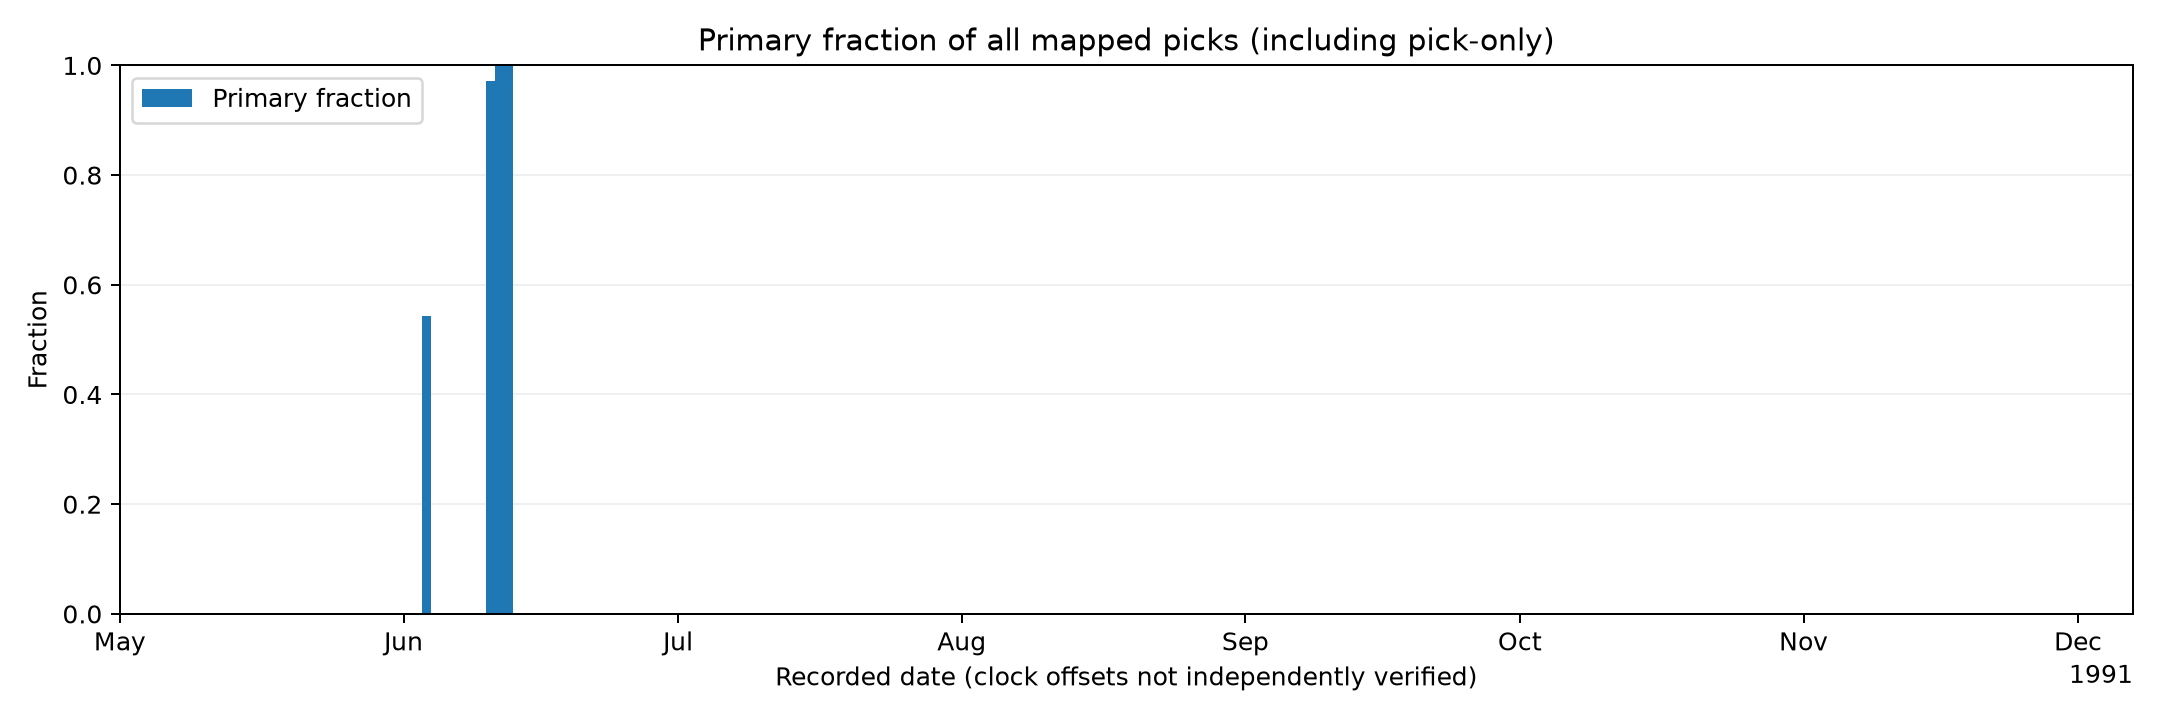

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/step33_event_association/33_waveform_coverage.png


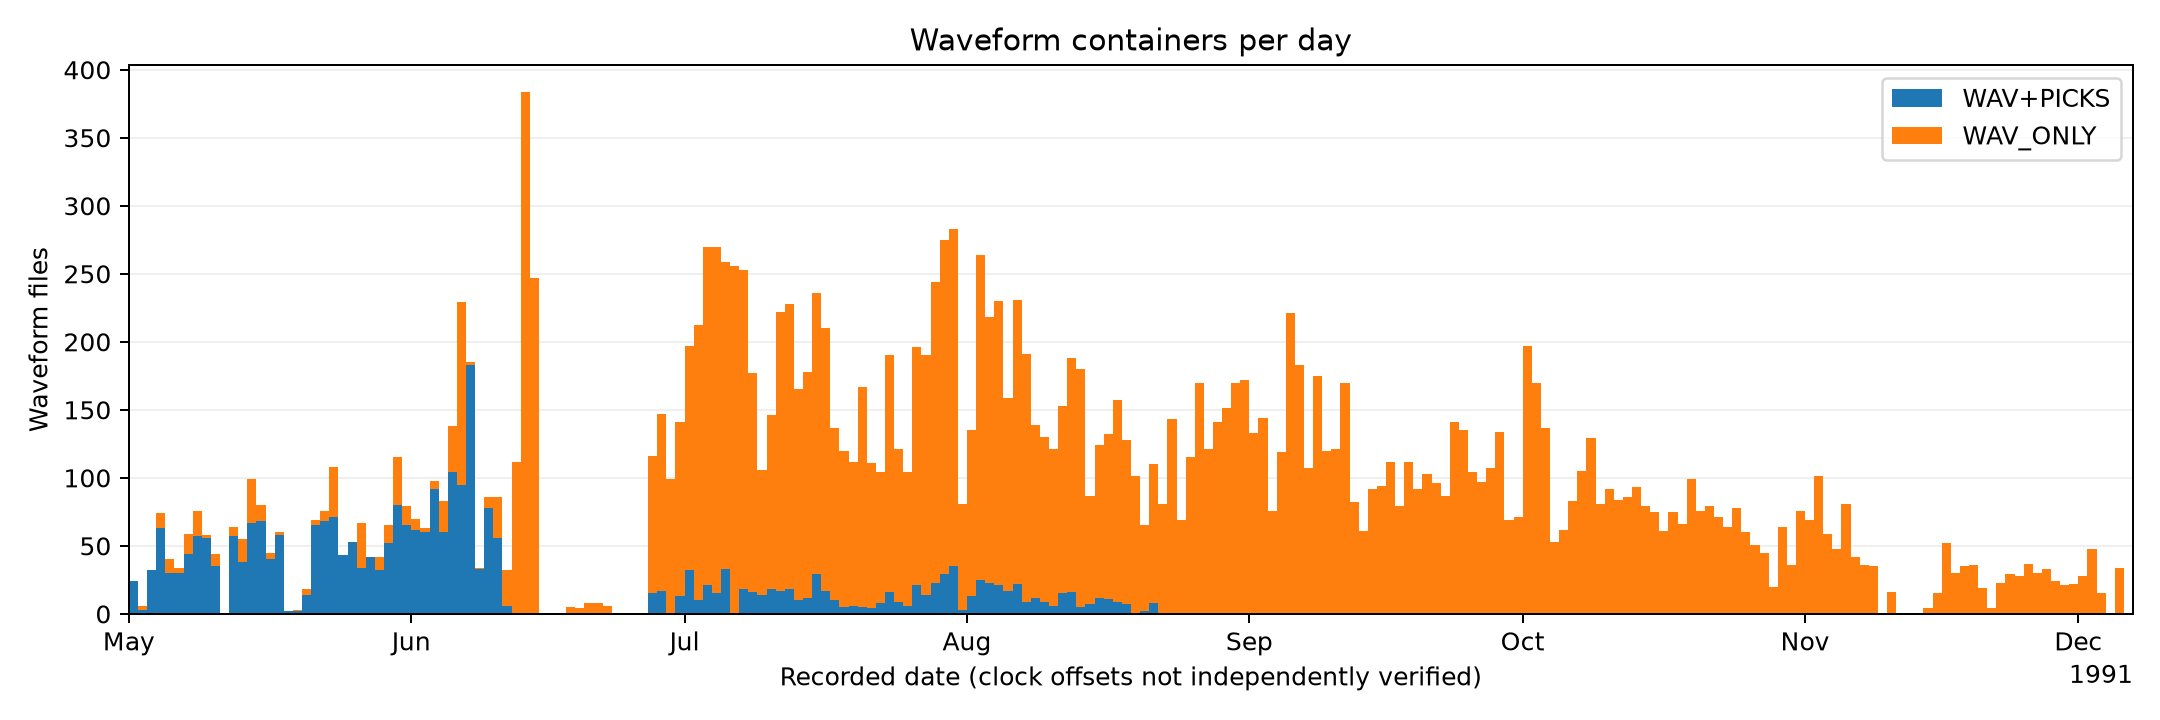

In [5]:
from IPython.display import Image

# Show saved diagnostics inline; all figures remain in the configured folder.
plot_roots = [Path(SETTINGS[k]) for k in ('outdir', 'out_dir', 'out')
              if k in SETTINGS and SETTINGS[k] is not None]
plots = sorted({p for root in plot_roots
                for p in ([root] if root.suffix.lower() == '.png'
                          else root.rglob('*.png')) if p.is_file()})
print(f'{len(plots)} saved PNG figures; showing up to four.')
for plot in plots[:4]:
    print(plot)
    display(Image(filename=str(plot)))
